# 6. Avaliação

**CatBoost aplicado à previsão de churn**

Atividade Final de Aprendizado de Máquina I · FATEC Jundiaí · Ciência de Dados

| Aluna | Professor | Tema |
|:--|:--|:--|
| Mariana Costa de Mello | Mateus Guilherme Fuini | CatBoost |

## Métricas

| Métrica | O que mede |
|:--|:--|
| ROC-AUC | Se o modelo coloca quem cancela acima de quem fica. Métrica principal |
| PR-AUC | Precisão x recall na classe positiva. O acaso dá 0,265 |
| Precisão e recall | Acerto das ações de retenção e churns encontrados, num limiar |
| Calibração e Brier | Se a probabilidade prevista bate com a frequência real |

## Preparação

A mesma preparação é usada em todos os notebooks:

- `TotalCharges` vem como texto e os 11 valores em branco são de clientes com 0 meses de casa, então viram 0
- `customerID` sai porque é só um identificador
- Divisão estratificada em 60% treino, 20% validação e 20% teste, com semente 42

A primeira célula instala as bibliotecas; o `%%capture` esconde as mensagens da instalação.

In [1]:
%%capture
%pip install catboost shap category_encoders

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from catboost import CatBoostClassifier, Pool
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score, precision_score, recall_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.precision", 3)
SEED = 42

df = pd.read_csv("https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv")
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0)
df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})

X = df.drop(columns=["customerID", "Churn"])
y = df["Churn"].eq("Yes").astype(int)
cats = X.select_dtypes(exclude="number").columns.tolist()

X_trval, X_test, y_trval, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_trval, y_trval, test_size=0.25, stratify=y_trval, random_state=SEED)

## Modelo final

Configuração vinda dos experimentos E2 e E3: `depth=4`, `learning_rate=0.03`, padrão nos demais parâmetros, com early stopping na validação.

O **limiar** de decisão é escolhido na validação, como o valor que dá o maior F1, e só depois aplicado ao teste.

In [3]:
modelo = CatBoostClassifier(iterations=3000, depth=4, learning_rate=0.03, eval_metric="AUC", early_stopping_rounds=200,
                            random_seed=SEED, verbose=0, cat_features=cats).fit(X_train, y_train, eval_set=(X_val, y_val))

limiares = np.arange(0.05, 0.95, 0.01)
limiar = limiares[np.argmax([f1_score(y_val, modelo.predict_proba(X_val)[:, 1] >= t) for t in limiares])]
proba = modelo.predict_proba(X_test)[:, 1]
print(f"Árvores: {modelo.tree_count_} | limiar escolhido na validação: {limiar:.2f}")

Árvores: 495 | limiar escolhido na validação: 0.37


## Resultado no teste

Comparação com os baselines. A regra do contrato mensal usa a taxa de churn de cada contrato no treino.

In [4]:
from sklearn.metrics import brier_score_loss

def avaliar(y_real, p, lim):
    pred = p >= lim
    return {"ROC-AUC": roc_auc_score(y_real, p), "PR-AUC": average_precision_score(y_real, p), "Precisão": precision_score(y_real, pred, zero_division=0),
            "Recall": recall_score(y_real, pred), "F1": f1_score(y_real, pred), "Brier": brier_score_loss(y_real, p)}

regra = X_test["Contract"].map(y_train.groupby(X_train["Contract"]).mean())
pd.DataFrame({
    "Classe majoritária": avaliar(y_test, np.zeros(len(y_test)), 0.5),
    "Contrato mensal": avaliar(y_test, regra, 0.3),
    "CatBoost (limiar 0,50)": avaliar(y_test, proba, 0.5),
    f"CatBoost (limiar {limiar:.2f})".replace(".", ","): avaliar(y_test, proba, limiar),
}).T.style.format("{:.3f}")

,ROC-AUC,PR-AUC,Precisão,Recall,F1,Brier
Classe majoritária,0.500,0.265,0.000,0.000,0.000,0.265
Contrato mensal,0.737,0.414,0.426,0.880,0.574,0.163
"CatBoost (limiar 0,50)",0.845,0.668,0.687,0.540,0.605,0.135
"CatBoost (limiar 0,37)",0.845,0.668,0.570,0.709,0.632,0.135


Intervalo de confiança de 95% da ROC-AUC com o `bootstrap` do SciPy, que reamostra o teste 1.000 vezes:

In [5]:
from scipy.stats import bootstrap

ic = bootstrap((y_test.values, proba), roc_auc_score, paired=True, vectorized=False, n_resamples=1000, method="percentile", random_state=SEED).confidence_interval
print(f"ROC-AUC = {roc_auc_score(y_test, proba):.3f} (IC 95%: {ic.low:.3f} a {ic.high:.3f})")

ROC-AUC = 0.845 (IC 95%: 0.824 a 0.865)


## Curvas

As quatro visões vêm prontas do scikit-learn (`from_predictions`):

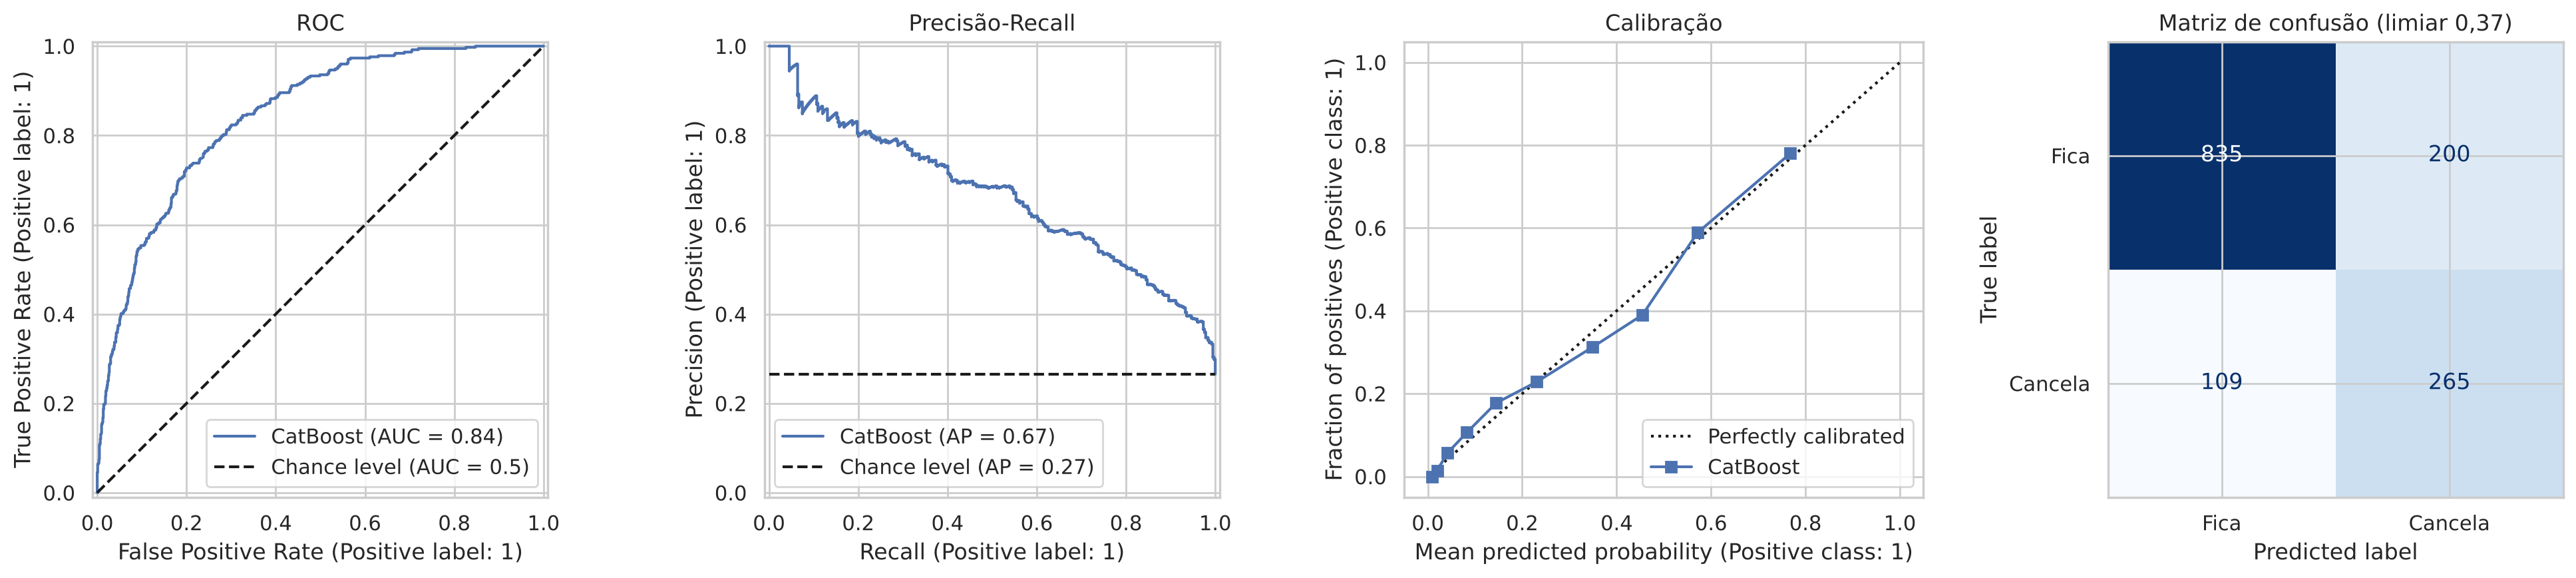

In [6]:
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay, ConfusionMatrixDisplay
from sklearn.calibration import CalibrationDisplay

fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
RocCurveDisplay.from_predictions(y_test, proba, name="CatBoost", ax=axes[0], plot_chance_level=True)
PrecisionRecallDisplay.from_predictions(y_test, proba, name="CatBoost", ax=axes[1], plot_chance_level=True)
CalibrationDisplay.from_predictions(y_test, proba, n_bins=10, strategy="quantile", name="CatBoost", ax=axes[2])
ConfusionMatrixDisplay.from_predictions(y_test, proba >= limiar, display_labels=["Fica", "Cancela"], cmap="Blues", colorbar=False, ax=axes[3])
for ax, titulo in zip(axes, ["ROC", "Precisão-Recall", "Calibração", f"Matriz de confusão (limiar {limiar:.2f})".replace(".", ",")]):
    ax.set_title(titulo)
plt.tight_layout()
plt.show()

### Curva de ganho

Quantos churns a empresa alcança contatando só os clientes de maior risco:

In [7]:
ganho = y_test.iloc[np.argsort(-proba)].cumsum() / y_test.sum()
pd.Series({f"Top {k}% da base": ganho.iloc[int(k / 100 * len(ganho)) - 1] for k in [10, 20, 30, 50]}, name="% dos churns").to_frame().style.format("{:.0%}")

,% dos churns
Top 10% da base,29%
Top 20% da base,51%
Top 30% da base,66%
Top 50% da base,87%


## Leitura dos resultados

| | Regra do contrato | CatBoost |
|:--|:--:|:--:|
| ROC-AUC | 0,737 | **0,845** |
| PR-AUC | 0,414 | **0,668** |
| Recall (limiar 0,37) | 0,880 | 0,709 |
| Precisão (limiar 0,37) | 0,426 | **0,570** |

- **ROC-AUC de 0,845** (IC 95%: 0,824 a 0,865), bem acima da regra de negócio e alinhada com a validação
- Com o limiar 0,37 o modelo encontra **71% dos churns** e acerta 57% das ações de retenção
- **Probabilidades calibradas**: a curva fica perto da diagonal (Brier 0,135)
- Contatando só os **20% de maior risco**, a empresa alcança **51% dos cancelamentos**

## Interpretação com SHAP

O `shap.TreeExplainer` calcula a contribuição de cada variável em cada previsão. Valores positivos puxam para o churn. Isso mostra o que o modelo usa, **não** causa e efeito.

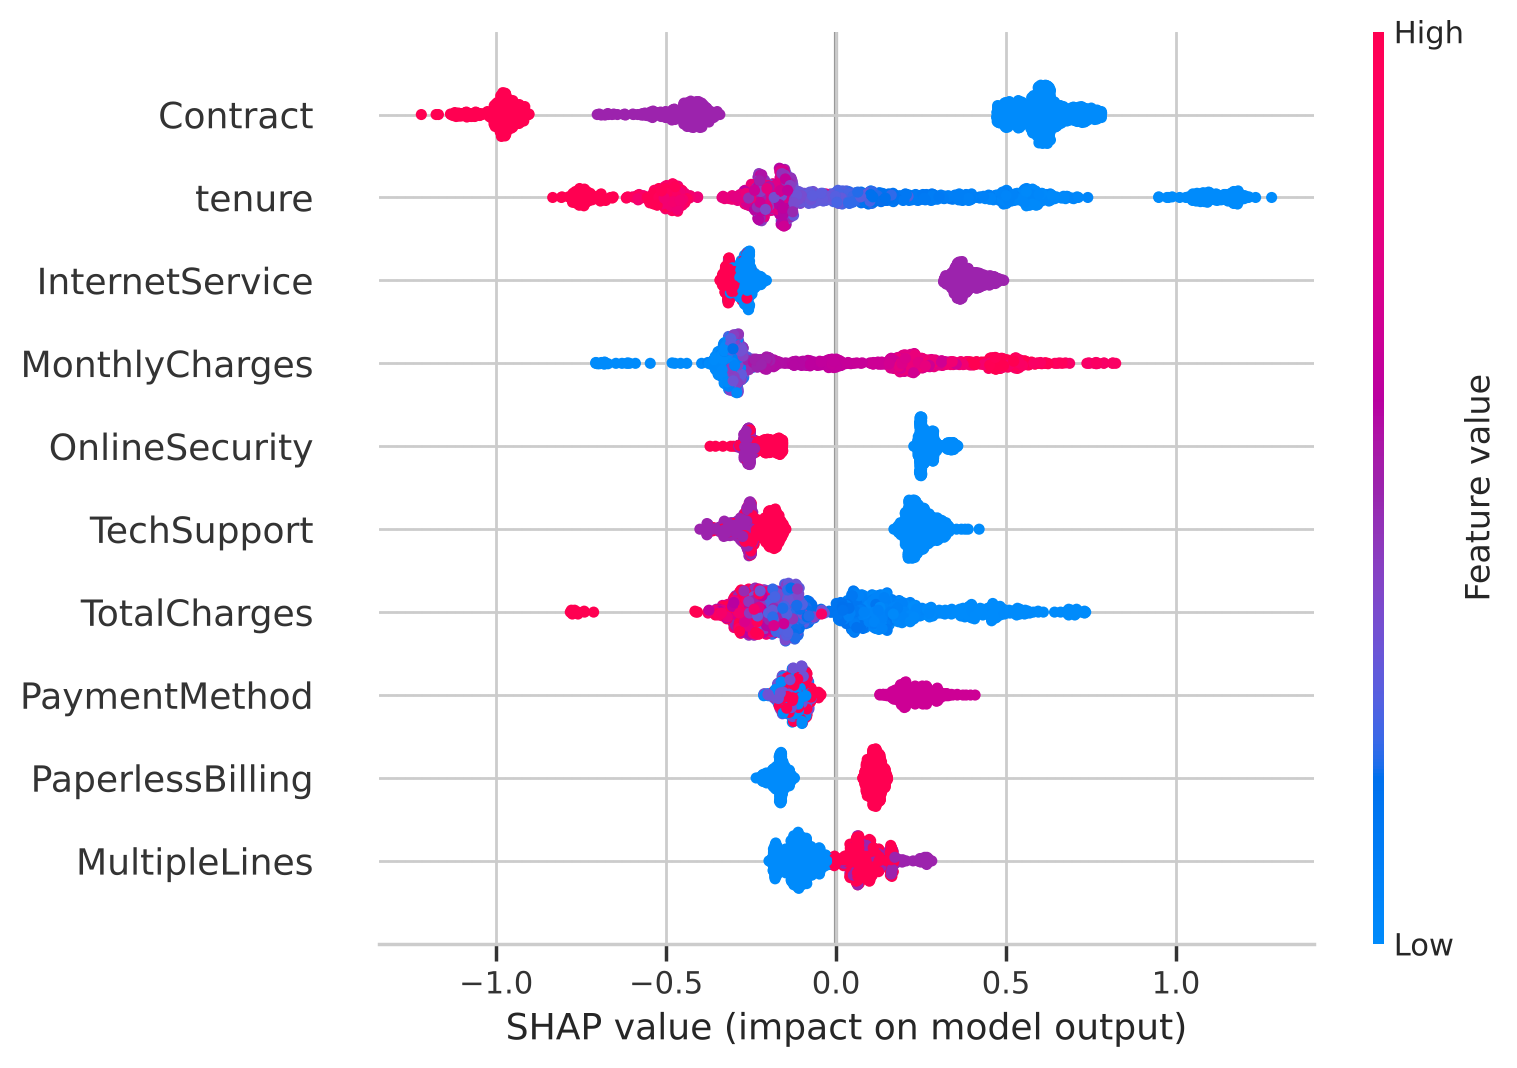

In [8]:
import shap

valores = shap.TreeExplainer(modelo).shap_values(Pool(X_test, cat_features=cats))
shap.summary_plot(valores, X_test.apply(lambda c: c.astype("category").cat.codes if c.name in cats else c), max_display=10)

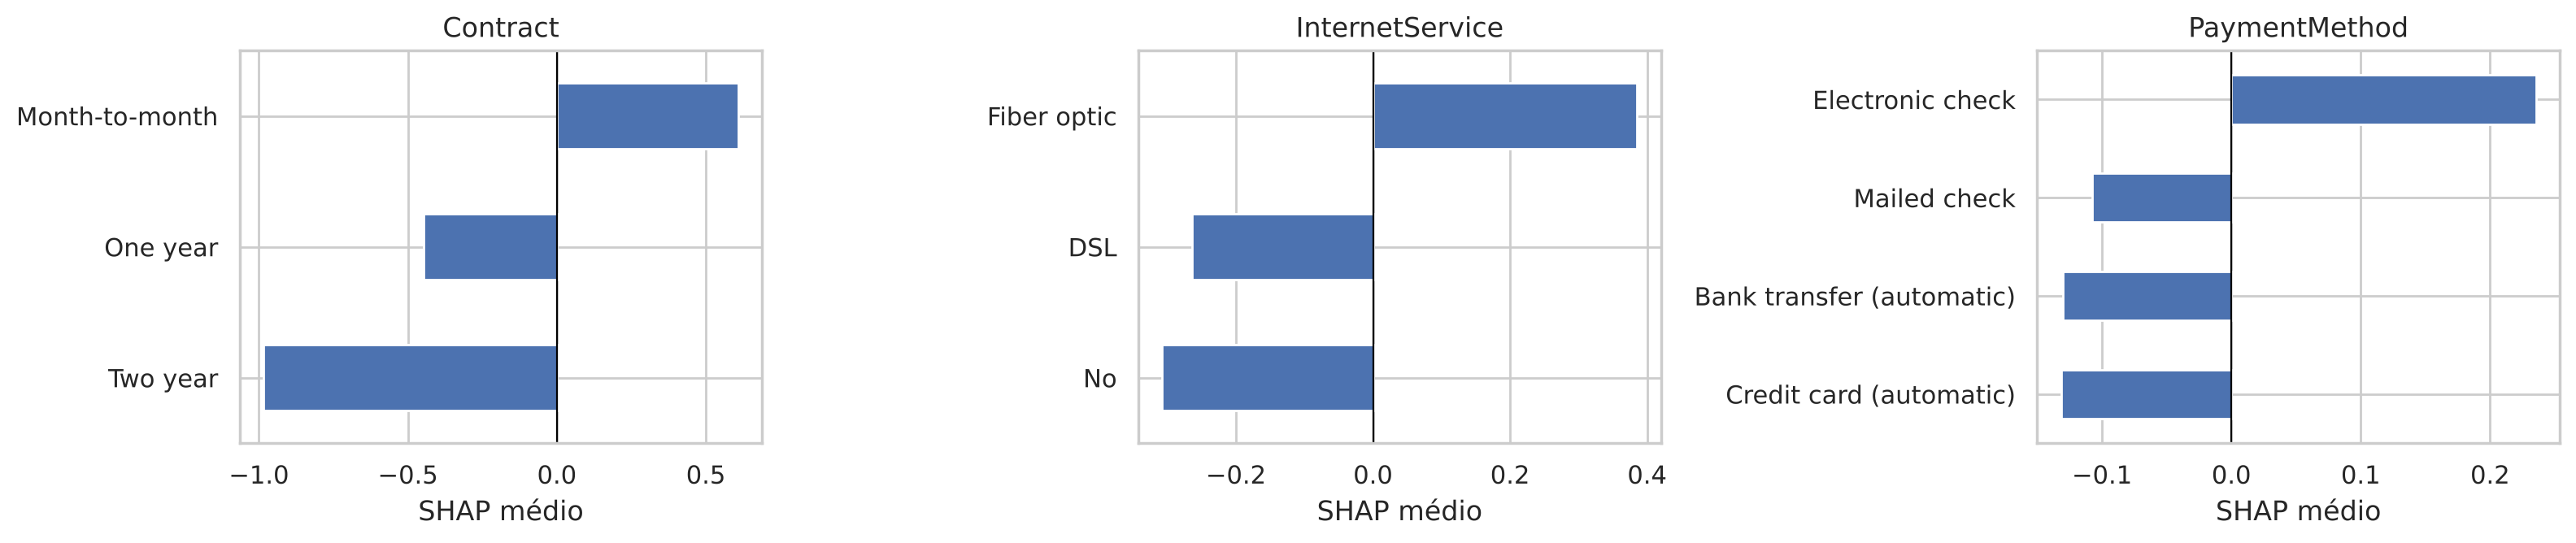

In [9]:
media = pd.DataFrame(valores, columns=X.columns, index=X_test.index)
fig, axes = plt.subplots(1, 3, figsize=(16, 3.5))
for ax, col in zip(axes, ["Contract", "InternetService", "PaymentMethod"]):
    media[col].groupby(X_test[col]).mean().sort_values().plot.barh(ax=ax, color="C0", title=col, xlabel="SHAP médio", ylabel="")
    ax.axvline(0, color="black", lw=0.8)
plt.tight_layout()
plt.show()

| Variável | Efeito no risco de churn |
|:--|:--|
| Contrato | Mensal aumenta; dois anos reduz bastante |
| Tempo de casa | Clientes novos têm mais risco |
| Internet | Fibra ótica aumenta; DSL e sem internet reduzem |
| Suporte e segurança online | Não ter aumenta |
| Pagamento | Cheque eletrônico aumenta; automáticos reduzem |

> Os padrões batem com a EDA do Notebook 4.

## Análise de erros

Perfil médio de cada tipo de acerto e erro no limiar escolhido.

In [10]:
tipo = np.select([(y_test == 1) & (proba >= limiar), (y_test == 0) & (proba >= limiar), (y_test == 1) & (proba < limiar)],
                 ["Churn detectado", "Alarme falso", "Churn perdido"], "Acerto (fica)")
X_test.assign(tipo=tipo, mensal=X_test["Contract"].eq("Month-to-month"), fibra=X_test["InternetService"].eq("Fiber optic")).groupby("tipo").agg(
    clientes=("tenure", "size"), tenure_medio=("tenure", "mean"), mensalidade=("MonthlyCharges", "mean"), contrato_mensal=("mensal", "mean"), fibra=("fibra", "mean"))

,clientes,tenure_medio,mensalidade,contrato_mensal,fibra
tipo,,,,,
Acerto (fica),835,42.272,57.111,0.297,0.250
Alarme falso,200,17.575,76.993,0.980,0.760
Churn detectado,265,11.868,76.412,0.992,0.800
Churn perdido,109,27.633,63.905,0.606,0.367


- **Churns perdidos** (109): clientes mais antigos (~28 meses) e com menos contrato mensal. Provavelmente saíram por motivos que não estão na base
- **Alarmes falsos** (200): perfil quase igual ao dos churns detectados (98% mensal, 76% fibra). Com as variáveis disponíveis não dá para separar
- Dados de comportamento (chamados, quedas de serviço, uso) ajudariam mais do que trocar de algoritmo